# Exp23 — Representation analysis the way Wu et al. (Semantic Hub) and Lim et al. do it

Same items, languages, models and anchors as Exp21/22, so these numbers can sit next to the patching results. No patching here: this notebook only reads hidden states, as the two papers do.

**From Wu et al. (Semantic Hub):**
- **Eq. 1 — relative cosine similarity.** Last-token hidden state of an item in language L vs its aligned item in the anchor language, minus the average similarity to non-matching items, separately per layer. Raw cosine (no centering), as in the paper. Their Fig. 3b shows this peaking in the middle layers, and BLOOM-7B included.
- **Eq. 3 — logit lens.** At each layer, is the probability of the English token larger than the probability of the input-language token? Reported as `en_gt_nat`.

**From Lim et al.:**
- **Latent probability of an answer phrase (their Eq. 7).** Logit lens decoded at every layer, with the answer tokens appended (Zhong et al.): the product of softmax(O h) over the phrase tokens, length-normalised.
- **Log ratio of native vs English answer choices** per layer: above 0 = the state sits in the language's own subspace; below 0 = the shared English-dominant space. Their Fig. 2a.
- **Latent accuracy** per layer: does the correct choice get the higher latent probability? Their Fig. 2b.
- **Their Table 2 analogue:** correlation, across language-by-task cells, between the mid-layer log ratio and (a) latent accuracy and (b) the patching compat from Exp21/22, if those result folders are present.

**English equivalents of the answer** exist for translation (the English source words), negation (the English adjective pair), agreement (the English verb forms), and gender (the English adjective lemma; the masculine and feminine forms share one English word). IOI uses the same English names in every language, so there is no native-vs-English contrast; it gets Eq. 1 and latent accuracy only.

**Differences from the papers:** two-choice items at one answer position instead of multi-choice QA; no steering experiments; 24 items per cell (20 for negation), so layer curves are noisy. In translation the English word is also in the prompt, which can inflate English probability.

The torch parts have not been run on a GPU (no torch in my sandbox); item building and all the numpy analysis were tested with a mock tokenizer and synthetic data.

In [1]:
import os
for v in ("HTTP_PROXY","HTTPS_PROXY","ALL_PROXY","http_proxy","https_proxy","all_proxy"):
    os.environ.pop(v, None)              # drop the broken proxy
os.environ["HF_HUB_OFFLINE"] = "1"       # use only cached/local files, no network calls

In [2]:
# CELL 1 — config + data (copied from Exp21; edit MODELS / GPU_ID / CELLS only)
import os
GPU_ID = 2
os.environ.setdefault("CUDA_VISIBLE_DEVICES", str(GPU_ID))
import json, math, random, itertools, warnings
from pathlib import Path
import numpy as np
OUT = Path("exp23_results"); OUT.mkdir(exist_ok=True); OUT21, OUT22 = Path("exp21_results"), Path("exp22_results")

MODELS = {"bloom-1b7": "bigscience/bloom-1b7", "bloom-7b1": "bigscience/bloom-7b1"}
def prepend_bos(key): return "gemma" in key
N_BASES, LAYER_STRIDE, SEED = 12, 2, 0        # items per cell = 2 * N_BASES (balanced labels)
KINDS = ("resid", "attn", "mlp")
FLOOR_MIN_FRAC = 0.30                         # compat valid only where same-language transfer >= this * mean|clean margin|
CELLS = {"ioi": ["en","fr","es","de","zh","ar","hi"], "negation": ["en","fr","es","zh"], "agreement": ["en","fr","es","hi"], "gender": ["fr","es","ar","hi"]}
ANCHOR     = {"ioi": "en", "negation": "en", "agreement": "en", "gender": "fr"}
ANCHOR_ALT = {"ioi": "fr", "negation": "fr", "agreement": "fr", "gender": "es"}      # donor language when the recipient IS the anchor
NV = {"ioi": 4, "negation": 2, "agreement": 2, "gender": 3}                          # surface variants per task
PRED_TASK_EPS = {"ioi": 0, "negation": 1, "agreement": 2, "gender": 3}                # ordinal, from task structure, written before running
SEP = {"zh": ""}

EN_NAMES = ["Mary","John","Tom","Anna","James","Sarah","David","Emily","Michael","Laura","Peter","Julia"]
TEMPLATES = {   # IOI: n1, n2 = first two mentions; n3 = repeated subject; final word constant per language
 "en": ["Then, {n1} and {n2} went to the shop. {n3} gave a drink to","After lunch, {n1} and {n2} went to the park. {n3} gave a book to",
        "When {n1} and {n2} got to the office, {n3} gave a letter to","Yesterday {n1} and {n2} were at the school. {n3} handed a pen to"],
 "fr": ["Ensuite, {n1} et {n2} sont allés au magasin. {n3} a donné une boisson à","Après le déjeuner, {n1} et {n2} sont allés au parc. {n3} a donné un livre à",
        "Quand {n1} et {n2} sont arrivés au bureau, {n3} a donné une lettre à","Hier, {n1} et {n2} étaient à l'école. {n3} a tendu un stylo à"],
 "es": ["Luego, {n1} y {n2} fueron a la tienda. {n3} le dio una bebida a","Después del almuerzo, {n1} y {n2} fueron al parque. {n3} le dio un libro a",
        "Cuando {n1} y {n2} llegaron a la oficina, {n3} le dio una carta a","Ayer {n1} y {n2} estaban en la escuela. {n3} le pasó un bolígrafo a"],
 "de": ["Dann gingen {n1} und {n2} zum Laden. {n3} gab ein Getränk an","Nach dem Mittagessen gingen {n1} und {n2} in den Park. {n3} gab ein Buch an",
        "Als {n1} und {n2} im Büro ankamen, gab {n3} einen Brief an","Gestern waren {n1} und {n2} in der Schule. {n3} reichte einen Stift an"],
 "zh": ["然后，{n1}和{n2}去了商店。{n3}把一杯饮料给","午饭后，{n1}和{n2}去了公园。{n3}把一本书给","当{n1}和{n2}到了办公室，{n3}把一封信给","昨天{n1}和{n2}在学校。{n3}把一支笔给"],
 "ar": ["ثم ذهب {n1} مع {n2} إلى المتجر. أعطى {n3} مشروبا إلى","بعد الغداء ذهب {n1} مع {n2} إلى الحديقة. أعطى {n3} كتابا إلى",
        "عندما وصل {n1} مع {n2} إلى المكتب، أعطى {n3} رسالة إلى","أمس كان {n1} مع {n2} في المدرسة. أعطى {n3} قلما إلى"],
 "hi": ["फिर {n1} और {n2} दुकान गए। {n3} ने","दोपहर के खाने के बाद {n1} और {n2} पार्क गए। {n3} ने","जब {n1} और {n2} दफ़्तर पहुँचे, तब {n3} ने","कल {n1} और {n2} स्कूल में थे। {n3} ने"],
}
NEG_FMT = {"en": ("{s1} is not {x}, so {s2} is", "{s1} is {x}, so {s2} is"), "fr": ("{s1} n'est pas {x}, donc {s2} est", "{s1} est {x}, donc {s2} est"),
           "es": ("{s1} no está {x}, así que {s2} está", "{s1} está {x}, así que {s2} está"), "zh": ("{s1}不是{x}，所以{s2}是", "{s1}是{x}，所以{s2}是")}
NEG = {   # (s1, s2, adj_a, adj_b); variant 0 = negated premise, 1 = affirmative premise
 "en": [("The door","the door","open","closed"),("The glass","the glass","full","empty"),("The soup","the soup","hot","cold"),("The towel","the towel","wet","dry"),("The room","the room","clean","dirty")],
 "fr": [("La porte","la porte","ouverte","fermée"),("Le verre","le verre","plein","vide"),("La soupe","la soupe","chaude","froide"),("La serviette","la serviette","mouillée","sèche"),("La chambre","la chambre","propre","sale")],
 "es": [("La puerta","la puerta","abierta","cerrada"),("El vaso","el vaso","lleno","vacío"),("La sopa","la sopa","caliente","fría"),("La toalla","la toalla","mojada","seca"),("La habitación","la habitación","limpia","sucia")],
 "zh": [("门","门","开着的","关着的"),("杯子","杯子","满的","空的"),("汤","汤","热的","冷的"),("毛巾","毛巾","湿的","干的"),("房间","房间","干净的","脏的")],
}
AGR = {   # head (sg, pl) x attractor PP (sg, pl) x verb (sg, pl); cand0 = singular form, cand1 = plural form
 "en": dict(heads=[("The author","The authors"),("The key","The keys"),("The teacher","The teachers"),("The pilot","The pilots")], pps=[("of the book","of the books"),("by the door","by the doors"),("near the car","near the cars")], verbs=[("is","are"),("was","were"),("has","have")]),
 "fr": dict(heads=[("L'auteur","Les auteurs"),("Le professeur","Les professeurs"),("Le pilote","Les pilotes"),("Le directeur","Les directeurs")], pps=[("du livre","des livres"),("de la porte","des portes"),("de la voiture","des voitures")], verbs=[("est","sont"),("a","ont"),("était","étaient")]),
 "es": dict(heads=[("El autor","Los autores"),("El profesor","Los profesores"),("El piloto","Los pilotos"),("El director","Los directores")], pps=[("del libro","de los libros"),("de la puerta","de las puertas"),("del coche","de los coches")], verbs=[("es","son"),("tiene","tienen"),("estaba","estaban")]),
 "hi": dict(heads=[("लड़का","लड़के"),("कुत्ता","कुत्ते"),("घोड़ा","घोड़े"),("बच्चा","बच्चे")], pps=[("मेज़ के पास","मेज़ों के पास"),("दरवाज़े के पास","दरवाज़ों के पास"),("कार के पास","कारों के पास")], verbs=[("है","हैं"),("था","थे")]),
}
GEN = {   # nouns: first 4 masculine, last 4 feminine (index-paired); cand0 = masculine adjective, cand1 = feminine adjective
 "fr": dict(fmt="Notre {n} est très", adjs=[("petit","petite"),("grand","grande"),("joli","jolie")], nouns=["livre","arbre","jardin","camion","table","voiture","main","nuit"]),
 "es": dict(fmt="Mi {n} es muy", adjs=[("nuevo","nueva"),("viejo","vieja"),("bonito","bonita")], nouns=["libro","coche","día","mapa","casa","mesa","mano","foto"]),
 "ar": dict(fmt="{n}", adjs=[("جديد","جديدة"),("كبير","كبيرة"),("جميل","جميلة")], nouns=["الباب","الكتاب","القلم","البيت","السيارة","الطاولة","الشمس","العين"]),
 "hi": dict(fmt="यह {n} बहुत", adjs=[("बड़ा","बड़ी"),("अच्छा","अच्छी"),("छोटा","छोटी")], nouns=["दरवाज़ा","कमरा","घर","पानी","कुर्सी","मेज़","किताब","रात"]),
}
print("config ok")

config ok


In [3]:
# CELL 2 — tokenizer helpers and aligned item grid (copied from Exp21)
def enc(tok, text): return tok(text, add_special_tokens=False)["input_ids"]
def new_tokens(tok, prefix, cont):
    a, b = enc(tok, prefix), enc(tok, prefix + cont)
    return b[len(a):] if b[:len(a)] == a else None

def all_bases(task, seed):
    if task == "ioi":
        cores = [(a, b, o) for a, b in itertools.permutations(EN_NAMES, 2) for o in ("ABBA", "BABA")]
    elif task == "negation": cores = [(p,) for p in range(5)]
    elif task == "agreement": cores = [(h, p, c) for h in range(4) for p in range(3) for c in (True, False)]
    elif task == "gender": cores = [(i,) for i in range(4)]
    bs = [(c, v) for c in cores for v in range(NV[task])]
    random.Random(seed).shuffle(bs); return bs

def render(task, lang, core, v, y):
    # returns (prefix, cand0, cand1, sep)
    sep = SEP.get(lang, " ")
    if task == "ioi":
        a, b, o = core; io, s = (a, b) if y == 0 else (b, a); n1, n2 = (io, s) if o == "ABBA" else (s, io)
        return TEMPLATES[lang][v].format(n1=n1, n2=n2, n3=s), a, b, sep
    if task == "negation":
        s1, s2, a, b = NEG[lang][core[0]]; fneg, faff = NEG_FMT[lang]
        x = (b if y == 0 else a) if v == 0 else (a if y == 0 else b)
        return (fneg if v == 0 else faff).format(s1=s1, s2=s2, x=x), a, b, sep
    if task == "agreement":
        h, p, cong = core; d = AGR[lang]; an = y if cong else 1 - y
        head, pp = d["heads"][h][y], d["pps"][p][an]
        prefix = f"{pp} {'का' if y == 0 else 'के'} {head}" if lang == "hi" else f"{head} {pp}"
        vs, vp = d["verbs"][v % len(d["verbs"])]; return prefix, vs, vp, sep
    if task == "gender":
        d = GEN[lang]; noun = d["nouns"][core[0] + (0 if y == 0 else 4)]; m, f = d["adjs"][v]
        return d["fmt"].format(n=noun), m, f, sep

def valid_render(tok, task, lang, core, v):
    for y in (0, 1):
        pr, c0, c1, sep = render(task, lang, core, v, y)
        if not (new_tokens(tok, pr, sep + c0) and new_tokens(tok, pr, sep + c1)): return False
    return True

def build_items(tok, task, lang, donor, n_bases, seed):
    out = []
    for core, v in all_bases(task, seed):
        v2 = (v + 1) % NV[task]
        if all(valid_render(tok, task, lg, core, vv) for lg, vv in ((lang, v), (lang, v2), (donor, v))): out.append((core, v))
        if len(out) >= n_bases: break
    return [dict(core=c, variant=v, y=y) for c, v in out for y in (0, 1)]
print("helpers ok")

helpers ok


In [4]:
# CELL 3 — translation items (as in Exp22) and English equivalents of each answer
import difflib, urllib.request
MUSE_DIR = Path("muse_dicts"); MUSE_URL = "https://dl.fbaipublicfiles.com/arrival/dictionaries/en-{l}.txt"
TR_LANGS = ["fr", "es", "de", "zh", "ar", "hi"]; N_DEMOS = 5; NV["translation"] = 3
LANGNAME = {"fr": "French", "es": "Spanish", "de": "German", "zh": "Chinese", "ar": "Arabic", "hi": "Hindi"}
CELLS["translation"] = list(TR_LANGS); ANCHOR["translation"], ANCHOR_ALT["translation"] = "fr", "es"
GEN_EN = {"fr": ["small", "big", "pretty"], "es": ["new", "old", "pretty"], "ar": ["new", "big", "beautiful"], "hi": ["big", "good", "small"]}   # English lemma of each gender adjective

def load_muse(l):
    p = MUSE_DIR / f"en-{l}.txt"
    if not p.exists():
        try: MUSE_DIR.mkdir(exist_ok=True); urllib.request.urlretrieve(MUSE_URL.format(l=l), p)
        except Exception as e: print("MUSE download failed for", l, e); return None
    return [tuple(x.split()) for x in p.read_text(encoding="utf-8").splitlines() if len(x.split()) == 2]
def clean_pairs(l, pairs):
    ss, tt, out = set(), set(), []
    for s, t in pairs:
        if not (s.isascii() and s.isalpha() and s.islower() and len(s) >= 3): continue
        if s in ss or t in tt or t.casefold() == s: continue
        if l in ("fr", "es", "de") and (not t.isalpha() or difflib.SequenceMatcher(None, s, t.casefold()).ratio() >= 0.8): continue
        ss.add(s); tt.add(t); out.append((s, t))
    return out
TR, TR_PAIRS = None, []
_d = {}
for _l in TR_LANGS:
    _p = load_muse(_l)
    if _p: _d[_l] = dict(clean_pairs(_l, _p))
if len(_d) == len(TR_LANGS):
    TR = _d; COMMON = sorted(set.intersection(*[set(d) for d in TR.values()])); random.Random(SEED).shuffle(COMMON)
    DEMO_C, TEST_C = COMMON[:40], COMMON[40:]; TR_PAIRS = [tuple(random.Random(SEED + i).sample(TEST_C, 2)) for i in range(400)]
    print("shared concepts:", len(COMMON))
else: CELLS.pop("translation"); print("translation skipped (MUSE files missing)")

def tr_render(lang, core, v, y):
    c, c2 = core; ds = random.Random(1000 + v).sample(DEMO_C, N_DEMOS)
    prefix = "".join(f"English: {w}\n{LANGNAME[lang]}: {TR[lang][w]}\n\n" for w in ds) + f"English: {c if y == 0 else c2}\n{LANGNAME[lang]}:"
    return prefix, TR[lang][c], TR[lang][c2], " "
_render_generic, _build_generic = render, build_items
def render_any(task, lang, core, v, y): return tr_render(lang, core, v, y) if task == "translation" else _render_generic(task, lang, core, v, y)
def build_any(tok, task, lang, donor, n_bases, seed):
    if task != "translation": return _build_generic(tok, task, lang, donor, n_bases, seed)
    out = []
    for core in TR_PAIRS:
        v = len(out) % NV["translation"]
        if all(all(new_tokens(tok, tr_render(lg, core, v, y)[0], " " + w) for y in (0, 1) for w in tr_render(lg, core, v, y)[1:3]) for lg in (lang, donor)): out.append((core, v))
        if len(out) >= n_bases: break
    return [dict(core=c, variant=v, y=y) for c, v in out for y in (0, 1)]

def en_equiv(task, lang, core, v):
    # English answer strings (e0, e1) for the two choices, or None when there is no native-vs-English contrast
    if lang == "en" or task == "ioi": return None
    if task == "negation": a, b = NEG["en"][core[0]][2:4]; return a, b
    if task == "agreement": return tuple(AGR["en"]["verbs"][v % len(AGR[lang]["verbs"])])
    if task == "gender": w = GEN_EN[lang][v]; return w, w
    if task == "translation": return core[0], core[1]
print("translation + English equivalents ready; cells:", {t: len(v) for t, v in CELLS.items()})

shared concepts: 2523
translation + English equivalents ready; cells: {'ioi': 7, 'negation': 4, 'agreement': 4, 'gender': 4, 'translation': 6}


In [5]:
# CELL 4 — numpy analysis (no GPU)
def _unit(X): return X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-9)

def hub_similarity(HA, HL):
    # Wu et al. Eq. 1: matched cosine minus average cosine to non-matching items, per layer. Items come in (y=0, y=1) flip pairs: i and i^1.
    n, nl, rows = HL.shape[0], HL.shape[1], []
    eye = np.eye(n, dtype=bool); partner = np.arange(n) ^ 1; nop = ~eye; nop[np.arange(n), partner] = False
    for l in range(nl):
        S = _unit(HL[:, l]) @ _unit(HA[:, l]).T; m = np.diag(S)
        b_all = np.array([S[i][~eye[i]].mean() for i in range(n)]); b_np = np.array([S[i][nop[i]].mean() for i in range(n)])
        Sc = _unit(HL[:, l] - HL[:, l].mean(0)) @ _unit(HA[:, l] - HA[:, l].mean(0)).T; mc = np.diag(Sc)
        bc = np.array([Sc[i][nop[i]].mean() for i in range(n)])
        rows.append(dict(layer=l, raw=float(m.mean()), baseline=float(b_all.mean()), rel=float((m - b_all).mean()), rel_nopartner=float((m - b_np).mean()), rel_centered=float((mc - bc).mean())))
    return rows

def lens_metrics(lp_nat, lp_en, y):
    # lp_nat, lp_en: [n, 2, nl] length-normalised log latent probability of choice 0 / 1 (Lim et al. Eq. 7); lp_en may be all-NaN
    n, _, nl = lp_nat.shape; idx = np.arange(n); rows = []
    for l in range(nl):
        nat_acc = float((lp_nat[idx, y, l] > lp_nat[idx, 1 - y, l]).mean())
        r = dict(layer=l, nat_acc=nat_acc, nat_correct_logp=float(lp_nat[idx, y, l].mean()))
        if np.isfinite(lp_en).any():
            pn, pe = np.exp(lp_nat[:, :, l]).mean(1), np.exp(lp_en[:, :, l]).mean(1)
            r.update(log_ratio=float(np.mean(np.log(pn + 1e-30) - np.log(pe + 1e-30))), en_acc=float((lp_en[idx, y, l] > lp_en[idx, 1 - y, l]).mean()),
                     en_gt_nat=float((lp_en[idx, y, l] > lp_nat[idx, y, l]).mean()))
        rows.append(r)
    return rows
print("analysis functions ok")

analysis functions ok


In [6]:
# CELL 5 — run (GPU): last-position states for item and anchor, plus logit-lens latent probabilities of native and English answer phrases
import torch, gc, time
from transformers import AutoTokenizer, AutoModelForCausalLM
dev = "cuda" if torch.cuda.is_available() else "cpu"

def get_modules(model):
    if hasattr(model, "transformer") and hasattr(model.transformer, "h"):
        return dict(resid=list(model.transformer.h), ln_f=model.transformer.ln_f, lm_head=model.lm_head)
    return dict(resid=list(model.model.layers), ln_f=model.model.norm, lm_head=model.lm_head)

@torch.no_grad()
def lens_run(model, mods, tok, bos, prefix, ans):
    # hidden states at positions p .. p+T-1 (each predicts the next answer token), decoded with the final norm + unembedding at every layer
    ids = bos + enc(tok, prefix); p = len(ids) - 1; T = len(ans); nl = len(mods["resid"]); store = [None] * nl; hs = []
    for li, m in enumerate(mods["resid"]):
        def hk(mod, inp, out, li=li):
            o = out[0] if isinstance(out, tuple) else out; store[li] = o[0, p:p + T].detach()
        hs.append(m.register_forward_hook(hk))
    try: out = model(input_ids=torch.tensor([ids + ans], device=dev))
    finally:
        for h in hs: h.remove()
    Hs = torch.stack(store)                                                  # [nl, T, H]
    lp = torch.log_softmax(mods["lm_head"](mods["ln_f"](Hs)).float(), -1)    # [nl, T, V]
    tgt = torch.tensor(ans, device=dev); ll = lp[:, torch.arange(T, device=dev), tgt].mean(1)      # length-normalised, [nl]
    real = torch.log_softmax(out.logits[0, p:p + T].float(), -1)[torch.arange(T, device=dev), tgt].mean().item()
    return ll.cpu().numpy(), Hs[:, 0].float().cpu().numpy(), real

@torch.no_grad()
def state_only(model, mods, tok, bos, prefix):
    ids = bos + enc(tok, prefix); p = len(ids) - 1; nl = len(mods["resid"]); store = [None] * nl; hs = []
    for li, m in enumerate(mods["resid"]):
        def hk(mod, inp, out, li=li):
            o = out[0] if isinstance(out, tuple) else out; store[li] = o[0, p].detach()
        hs.append(m.register_forward_hook(hk))
    try: model(input_ids=torch.tensor([ids], device=dev))
    finally:
        for h in hs: h.remove()
    return torch.stack(store).float().cpu().numpy()

for key, path in MODELS.items():
    tok = AutoTokenizer.from_pretrained(path); bos = [tok.bos_token_id] if prepend_bos(key) else []
    model = AutoModelForCausalLM.from_pretrained(path, torch_dtype=torch.bfloat16).to(dev).eval(); mods = get_modules(model); nl = len(mods["resid"]); H = mods["lm_head"].weight.shape[1]
    checked = False
    for task, langs in CELLS.items():
        for L in langs:
            f = OUT / f"{key}__{task}__{L}.npz"
            if f.exists(): print("cached", f.name); continue
            D = ANCHOR[task] if L != ANCHOR[task] else ANCHOR_ALT[task]; items = build_any(tok, task, L, D, N_BASES, SEED)
            if len(items) < 12: print("SKIP", key, task, L, len(items)); continue
            n, t0 = len(items), time.time(); y = np.array([it["y"] for it in items])
            HL = np.zeros((n, nl, H), np.float32); HA = np.zeros_like(HL); lpn = np.zeros((n, 2, nl)); lpe = np.full((n, 2, nl), np.nan)
            for i, it in enumerate(items):
                core, v, yy = it["core"], it["variant"], it["y"]; pr, c0, c1, sep = render_any(task, L, core, v, yy)
                for j, c in enumerate((c0, c1)):
                    ans = new_tokens(tok, pr, sep + c); lpn[i, j], st, real = lens_run(model, mods, tok, bos, pr, ans)
                    if j == 0: HL[i] = st
                    if not checked and "gemma" not in key: print(f"sanity: last-layer lens {lpn[i, j, -1]:.3f} vs model {real:.3f}"); checked = True
                eq = en_equiv(task, L, core, v)
                if eq:
                    for j, w in enumerate(eq):
                        ans = new_tokens(tok, pr, sep + w)
                        if ans: lpe[i, j] = lens_run(model, mods, tok, bos, pr, ans)[0]
                HA[i] = state_only(model, mods, tok, bos, render_any(task, D, core, v, yy)[0])
            np.savez(f, y=y, HL=HL, HA=HA, lp_nat=lpn, lp_en=lpe, donor=np.array(D)); print(f"saved {f.name} n={n} {time.time() - t0:.0f}s")
    del model; gc.collect(); torch.cuda.empty_cache()

/home/anwoy/miniconda3/envs/ke/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
`torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 293/293 [00:00<00:00, 2318.41it/s]


sanity: last-layer lens -0.955 vs model -0.955
saved bloom-1b7__ioi__en.npz n=24 1s
saved bloom-1b7__ioi__fr.npz n=24 1s
saved bloom-1b7__ioi__es.npz n=24 1s
saved bloom-1b7__ioi__de.npz n=24 1s
saved bloom-1b7__ioi__zh.npz n=24 1s
saved bloom-1b7__ioi__ar.npz n=24 1s
saved bloom-1b7__ioi__hi.npz n=24 1s
saved bloom-1b7__negation__en.npz n=20 0s
saved bloom-1b7__negation__fr.npz n=20 1s
saved bloom-1b7__negation__es.npz n=20 1s
saved bloom-1b7__negation__zh.npz n=20 1s
saved bloom-1b7__agreement__en.npz n=24 1s
saved bloom-1b7__agreement__fr.npz n=24 1s
saved bloom-1b7__agreement__es.npz n=24 1s
saved bloom-1b7__agreement__hi.npz n=24 1s
saved bloom-1b7__gender__fr.npz n=24 1s
saved bloom-1b7__gender__es.npz n=24 1s
saved bloom-1b7__gender__ar.npz n=24 1s
saved bloom-1b7__gender__hi.npz n=24 1s
saved bloom-1b7__translation__fr.npz n=24 1s
saved bloom-1b7__translation__es.npz n=24 1s
saved bloom-1b7__translation__de.npz n=24 1s
saved bloom-1b7__translation__zh.npz n=24 1s
saved bloom-1b

Loading weights: 100%|██████████| 365/365 [00:00<00:00, 959.88it/s] 


sanity: last-layer lens -0.467 vs model -0.467
saved bloom-7b1__ioi__en.npz n=24 1s
saved bloom-7b1__ioi__fr.npz n=24 1s
saved bloom-7b1__ioi__es.npz n=24 1s
saved bloom-7b1__ioi__de.npz n=24 1s
saved bloom-7b1__ioi__zh.npz n=24 1s
saved bloom-7b1__ioi__ar.npz n=24 1s
saved bloom-7b1__ioi__hi.npz n=24 1s
saved bloom-7b1__negation__en.npz n=20 1s
saved bloom-7b1__negation__fr.npz n=20 1s
saved bloom-7b1__negation__es.npz n=20 1s
saved bloom-7b1__negation__zh.npz n=20 1s
saved bloom-7b1__agreement__en.npz n=24 1s
saved bloom-7b1__agreement__fr.npz n=24 1s
saved bloom-7b1__agreement__es.npz n=24 1s
saved bloom-7b1__agreement__hi.npz n=24 1s
saved bloom-7b1__gender__fr.npz n=24 1s
saved bloom-7b1__gender__es.npz n=24 1s
saved bloom-7b1__gender__ar.npz n=24 1s
saved bloom-7b1__gender__hi.npz n=24 1s
saved bloom-7b1__translation__fr.npz n=24 1s
saved bloom-7b1__translation__es.npz n=24 1s
saved bloom-7b1__translation__de.npz n=24 1s
saved bloom-7b1__translation__zh.npz n=24 1s
saved bloom-7b

    model        task lang donor  n  hub_rel_mid  hub_rel_nopartner_mid  hub_rel_peak_layer  nat_acc_mid  nat_acc_last  log_ratio_mid  en_gt_nat_mid  en_acc_mid
bloom-1b7   agreement   en    fr 24        0.187                  0.193                   4         0.72          0.92            NaN            NaN         NaN
bloom-1b7   agreement   es    en 24        0.197                  0.203                   0         0.53          1.00          -0.31           0.59        0.71
bloom-1b7   agreement   fr    en 24        0.187                  0.193                   4         0.62          1.00           0.48           0.41        0.63
bloom-1b7   agreement   hi    en 24        0.006                  0.006                   6         0.88          1.00          -3.20           0.94        0.72
bloom-1b7      gender   ar    fr 24       -0.000                 -0.000                  23         0.75          1.00          -1.32           0.75        0.00
bloom-1b7      gender   es    fr 2

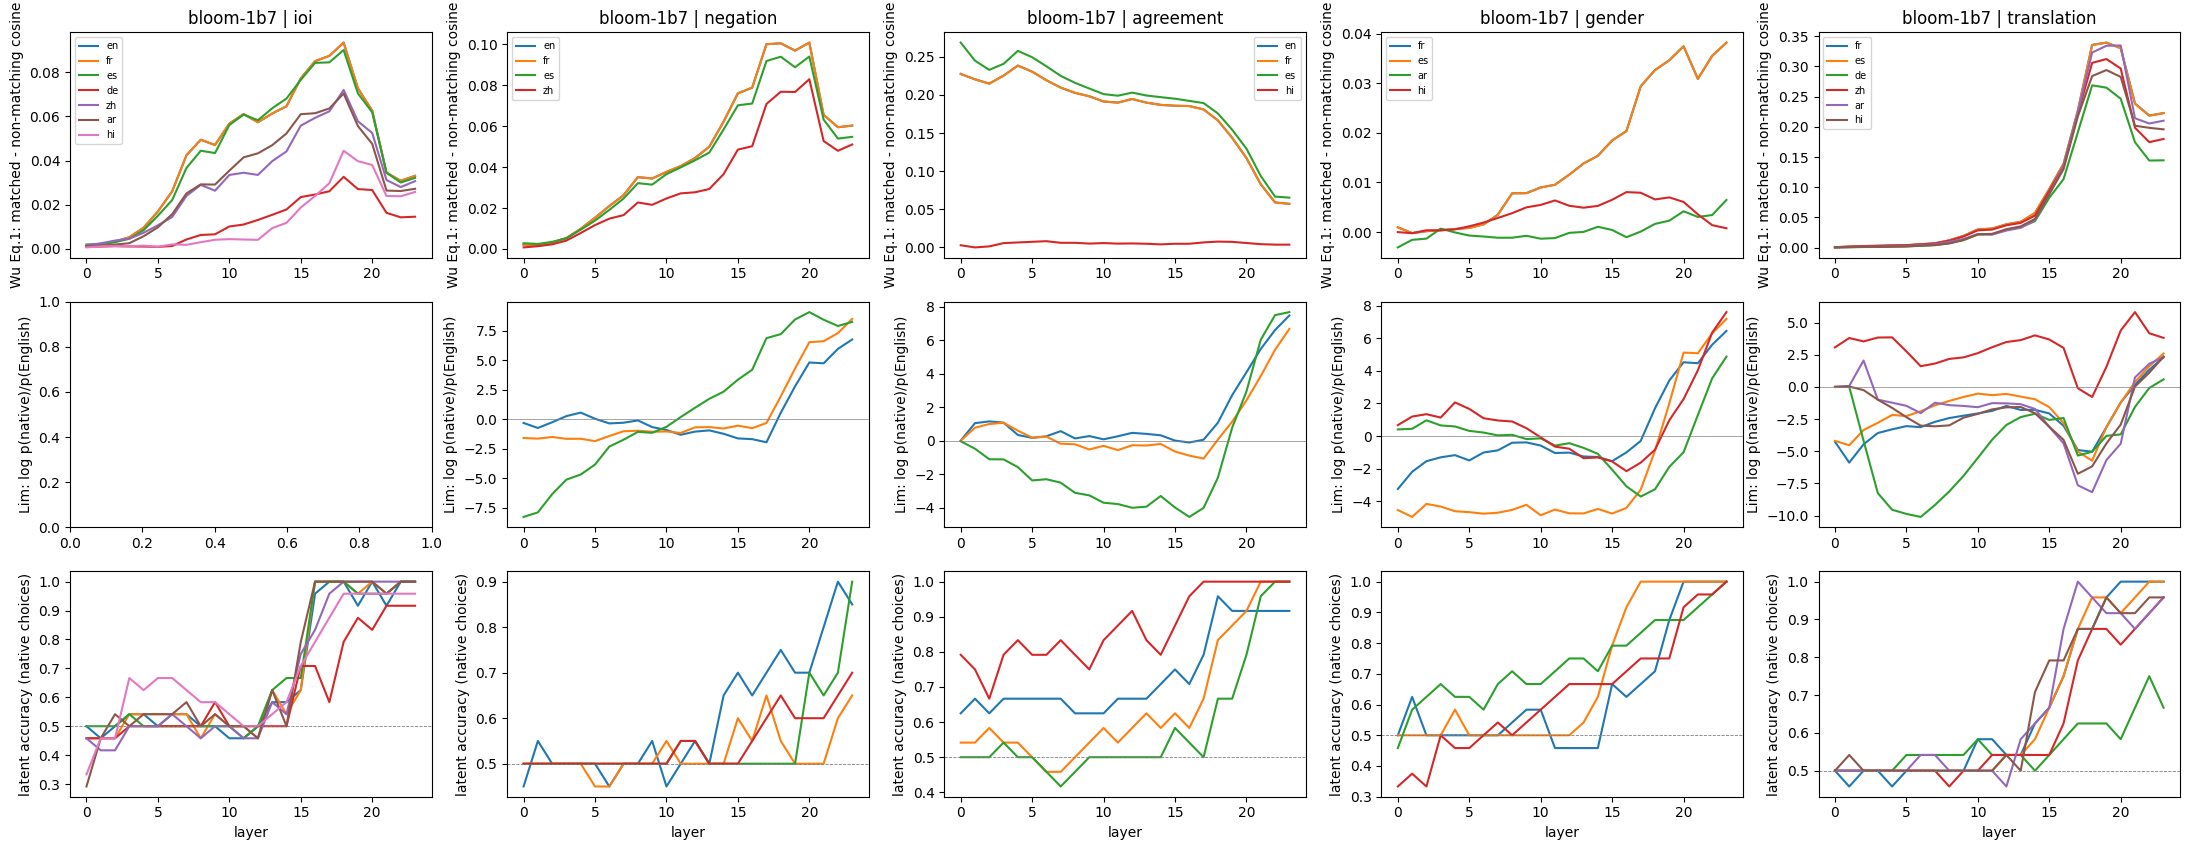

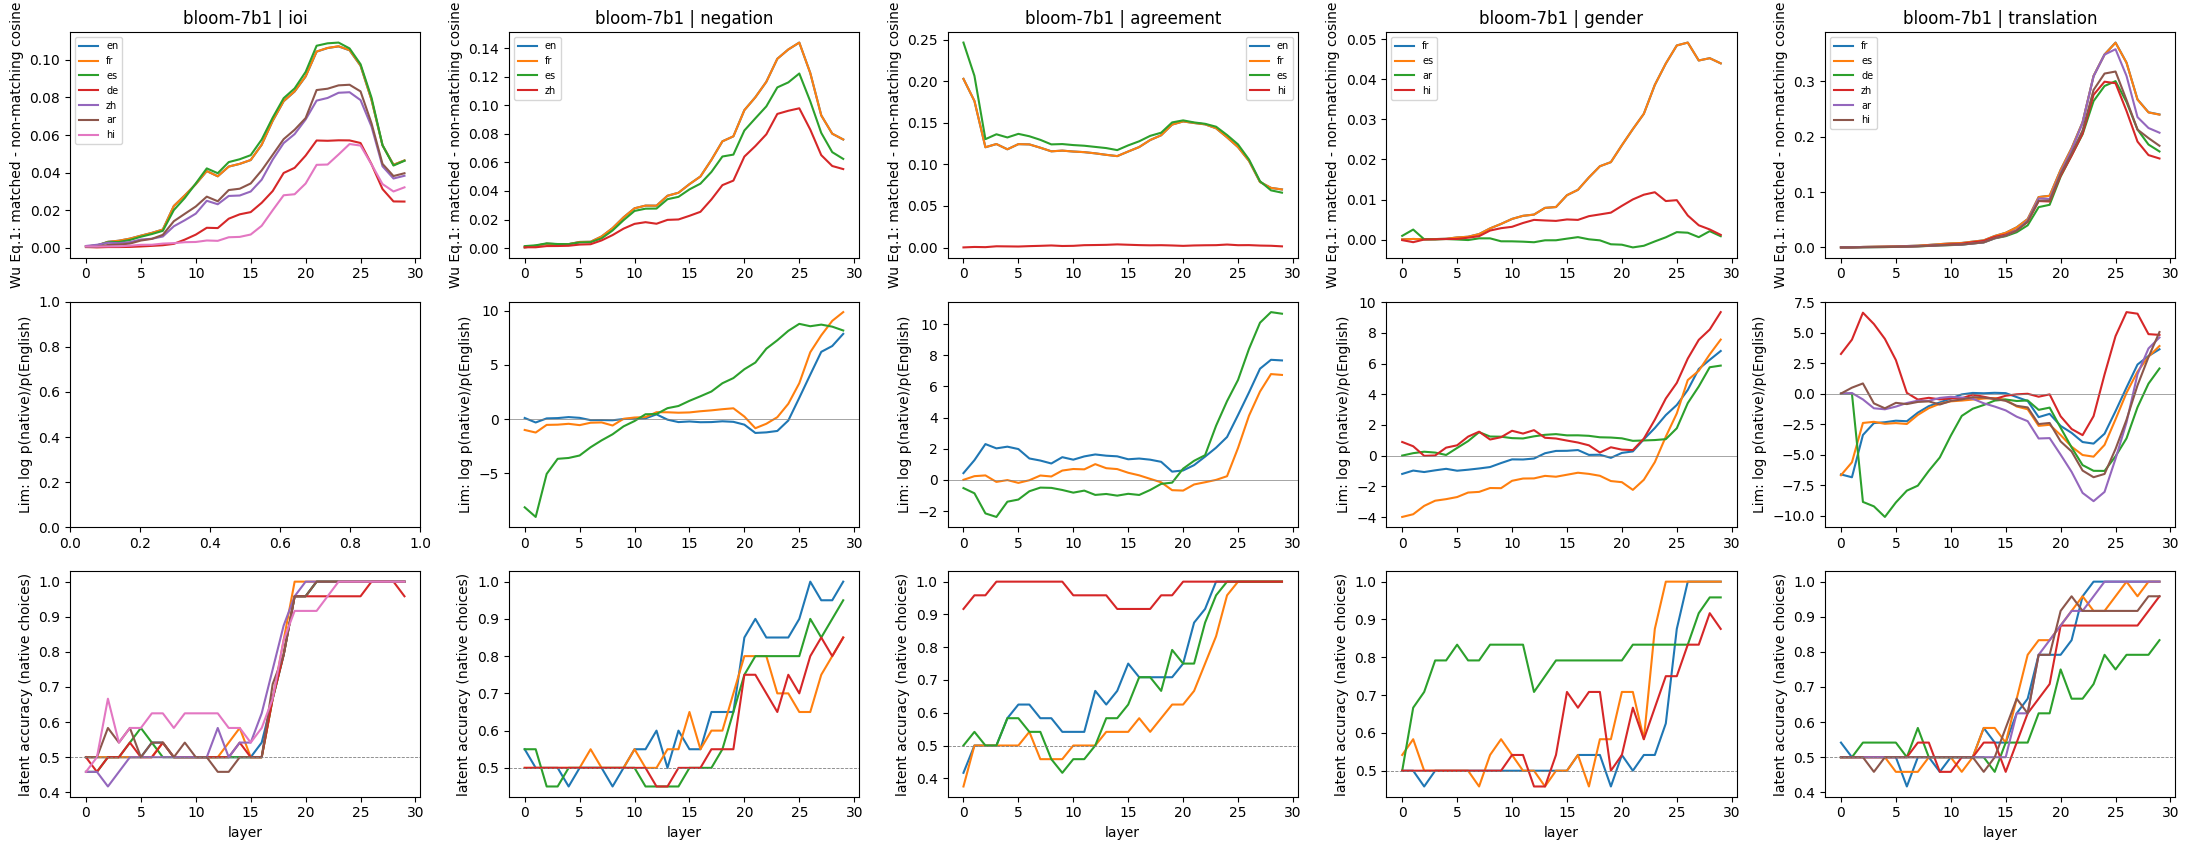

In [7]:
# CELL 6 — analysis from saved results (no GPU): per-layer tables, figures, and the Lim-style correlations
import pandas as pd
MID = (0.30, 0.80)                                   # fraction of depth treated as "middle layers"
rows_h, rows_l, rows_s = [], [], []
for f in sorted(OUT.glob("*.npz")):
    key, task, L = f.stem.split("__"); z = np.load(f); y = z["y"]; assert all(y[::2] == 0) and all(y[1::2] == 1)
    hub = hub_similarity(z["HA"], z["HL"]); lens = lens_metrics(z["lp_nat"], z["lp_en"], y); nl = len(hub); lo, hi = int(MID[0] * nl), int(MID[1] * nl) + 1
    for r in hub: r.update(model=key, task=task, lang=L); rows_h.append(r)
    for r in lens: r.update(model=key, task=task, lang=L); rows_l.append(r)
    dh, dl = pd.DataFrame(hub), pd.DataFrame(lens)
    s = dict(model=key, task=task, lang=L, donor=str(z["donor"]), n=len(y), hub_rel_mid=round(dh.rel[lo:hi].mean(), 3), hub_rel_nopartner_mid=round(dh.rel_nopartner[lo:hi].mean(), 3),
             hub_rel_peak_layer=int(dh.rel.idxmax()), nat_acc_mid=round(dl.nat_acc[lo:hi].mean(), 2), nat_acc_last=round(dl.nat_acc.iloc[-1], 2))
    if "log_ratio" in dl: s.update(log_ratio_mid=round(dl.log_ratio[lo:hi].mean(), 2), en_gt_nat_mid=round(dl.en_gt_nat[lo:hi].mean(), 2), en_acc_mid=round(dl.en_acc[lo:hi].mean(), 2))
    rows_s.append(s)
df_h, df_l, df_s = pd.DataFrame(rows_h), pd.DataFrame(rows_l), pd.DataFrame(rows_s).sort_values(["model", "task", "lang"])
pd.set_option("display.width", 250); print(df_s.to_string(index=False))
print("\nhub_rel: Wu Eq.1 (matched minus non-matching cosine) averaged over the middle layers; log_ratio: Lim native-vs-English (>0 = native subspace); en_gt_nat: Wu Eq.3; nat_acc/en_acc: latent accuracy (chance 0.5).")
df_h.to_csv(OUT / "hub_per_layer.csv", index=False); df_l.to_csv(OUT / "lens_per_layer.csv", index=False); df_s.to_csv(OUT / "summary_rep.csv", index=False)

# Lim Table-2 analogue: across (task, language) cells, does leaving the shared space go with lower latent accuracy / lower patching compat?
comp = {}
if (OUT21 / "summary.csv").exists():
    for _, r in pd.read_csv(OUT21 / "summary.csv").iterrows(): comp[(r.model, r.task, r.lang)] = r.C_resid
if (OUT22 / "translation_per_layer.csv").exists():
    t = pd.read_csv(OUT22 / "translation_per_layer.csv"); t = t[t.kind == "summary"]
    for _, r in t.iterrows(): comp[(r.model, "translation", r.lang)] = r.C_resid
df_s["C_resid"] = [comp.get((r.model, r.task, r.lang), np.nan) for r in df_s.itertuples()]
from scipy.stats import pearsonr, spearmanr
for key in df_s.model.unique():
    d = df_s[(df_s.model == key) & df_s.get("log_ratio_mid", pd.Series(dtype=float)).notna()] if "log_ratio_mid" in df_s else pd.DataFrame()
    for ycol in ("nat_acc_mid", "C_resid", "hub_rel_mid"):
        dd = d[["log_ratio_mid", ycol]].dropna() if len(d) else d
        if len(dd) >= 5: print(f"{key}: log_ratio_mid vs {ycol}: n={len(dd)}  pearson={pearsonr(dd.log_ratio_mid, dd[ycol])[0]:.2f}  spearman={spearmanr(dd.log_ratio_mid, dd[ycol])[0]:.2f}")
df_s.to_csv(OUT / "summary_rep.csv", index=False)

import matplotlib.pyplot as plt
for key in df_s.model.unique():
    tasks = [t for t in CELLS if ((df_s.model == key) & (df_s.task == t)).any()]
    fig, axs = plt.subplots(3, len(tasks), figsize=(4.4 * len(tasks), 8.6), squeeze=False)
    for j, t in enumerate(tasks):
        for L in CELLS[t]:
            h = df_h[(df_h.model == key) & (df_h.task == t) & (df_h.lang == L)]; l = df_l[(df_l.model == key) & (df_l.task == t) & (df_l.lang == L)]
            if len(h): axs[0][j].plot(h.layer, h.rel, label=L)
            if "log_ratio" in l and l.log_ratio.notna().any(): axs[1][j].plot(l.layer, l.log_ratio, label=L)
            if len(l): axs[2][j].plot(l.layer, l.nat_acc, label=L)
        axs[0][j].set_title(f"{key} | {t}"); axs[0][j].set_ylabel("Wu Eq.1: matched - non-matching cosine"); axs[1][j].axhline(0, color="gray", lw=.5); axs[1][j].set_ylabel("Lim: log p(native)/p(English)")
        axs[2][j].axhline(.5, color="gray", ls="--", lw=.6); axs[2][j].set_ylabel("latent accuracy (native choices)"); axs[2][j].set_xlabel("layer"); axs[0][j].legend(fontsize=7)
    plt.tight_layout(); plt.savefig(OUT / f"representation_{key}.png", dpi=140); plt.show()